# Figure 3: Mentioning without citing

Rebuild the comparison between papers that mention an open-source package and papers that cite its own papers, for the nine packages whose papers Europe PMC indexes. See `MANUSCRIPT/01_MAIN.md`, Results, Many papers mention a package without citing it, and Methods, Mentions and citations.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig3_citations as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Query construction

Europe PMC links each parsed reference to the record it cites. A paper cites a package when one of its references links, through the `CITES` field, to one of the package's own papers listed in `config/package_papers.yml`. Mention queries carry a trailing wildcard because the index joins a package name to a following citation number ("QuPath63").


In [2]:
from census.build import build_citations as bc
own = bc.own_papers()
jobs = bc.build_queries(reg, own)
for key in [('qupath', 2025, k) for k in ('named', 'cited', 'both')]:
    print(key, jobs[key])
print(pd.Series({t: bc.cite_clause(t, own)[0] for t in bc.REF_TERMS}).to_string())
print(bc.first_paper_year())

('qupath', 2025, 'named') QuPath* AND ((microscopy OR microscope) AND HAS_FT:Y) AND PUB_YEAR:2025
('qupath', 2025, 'cited') (CITES:29203879_MED) AND ((microscopy OR microscope) AND HAS_FT:Y) AND PUB_YEAR:2025
('qupath', 2025, 'both') QuPath* AND ((microscopy OR microscope) AND HAS_FT:Y) AND (CITES:29203879_MED) AND PUB_YEAR:2025
imagej             links
qupath             links
cellprofiler       links
ilastik            links
napari            titles
icy                links
knime             titles
cellpose           links
stardist          titles
deepimagej         links
zerocostdl4mic     links
jupyter           titles
skimage            links
opencv            titles
{'imagej': 2012, 'qupath': 2017, 'cellprofiler': 2006, 'ilastik': 2019, 'icy': 2012, 'cellpose': 2021, 'deepimagej': 2021, 'zerocostdl4mic': 2021, 'skimage': 2014}


In [3]:
inspect_processed('mentions_citations_yearly.csv')

mentions_citations_yearly.csv: shape=(224, 8)


,tool_id,method,year,named,cited,both,named_not_cited,cited_not_named
0,imagej,links,2010,4314,0,0,4314,0
1,imagej,links,2011,5957,0,0,5957,0
2,imagej,links,2012,7781,39,39,7742,0
3,imagej,links,2013,9824,422,382,9442,40
4,imagej,links,2014,11405,848,789,10616,59


,tool_id,method,year,named,cited,both,named_not_cited,cited_not_named
0,imagej,links,2010,4314,0,0,4314,0
1,imagej,links,2011,5957,0,0,5957,0
2,imagej,links,2012,7781,39,39,7742,0
3,imagej,links,2013,9824,422,382,9442,40
4,imagej,links,2014,11405,848,789,10616,59
...,...,...,...,...,...,...,...,...
219,opencv,titles,2021,220,68,57,163,11
220,opencv,titles,2022,302,121,99,203,22
221,opencv,titles,2023,290,109,87,203,22
222,opencv,titles,2024,341,91,73,268,18


## Counts as indexed

The figure uses the counts as Europe PMC indexes them, with no correction. The sampled checks of index misses are summarised in the supplement (query-error table). Panel a splits the 2021-2025 union into mentioned, not cited, mentioned and cited, and cited, not mentioned, with rows ordered by the mentioned, not cited share. Panel b gives that share in 2020, or the first eligible later year with at least 20 mentioning papers after the package's first own paper, and in 2025. Its rows align with panel a.


In [4]:
table = figure.table()
display(figure.union(table).round(1))
display(figure.yearly().pivot(index='year', columns='tool_id', values='share').round(0))
union = figure.union(table)
change = figure.change()
yearly = figure.yearly().set_index(['tool_id', 'year'])['share']
assert set(change.index) <= set(union.index)
for tool_id, row in change.iterrows():
    first = min(year for year in yearly.loc[tool_id].index if 2020 <= year < 2025)
    assert first == int(row.start_year), (tool_id, first, int(row.start_year))
    np.testing.assert_allclose([yearly.loc[(tool_id, int(row.start_year))], yearly.loc[(tool_id, 2025)]],
                               [row.start, row.end], rtol=1e-12)
assert set(union.index) - set(change.index) == {'deepimagej'}
display(change.assign(start_year=change.start_year.astype(int)).round(1))
print(f'Panel b covers {len(change)} of the {len(union)} packages; Cellpose and ZCDL4M/DL4ME start in 2022 and deepImageJ has fewer than 20 mentioning papers a year.')


,label,no,both,co,total,no_pct,both_pct,co_pct
tool_id,,,,,,,,
cellpose,Cellpose,350,1475,211,2036,17.2,72.4,10.4
cellprofiler,CellProfiler,2419,2098,319,4836,50.0,43.4,6.6
deepimagej,deepImageJ,17,56,48,121,14.0,46.3,39.7
icy,Icy,198,129,238,565,35.0,22.8,42.1
ilastik,ilastik,514,1029,136,1679,30.6,61.3,8.1
imagej,ImageJ/Fiji,176887,26527,1550,204964,86.3,12.9,0.8
qupath,QuPath,2308,2459,67,4834,47.7,50.9,1.4
skimage,scikit-image,765,594,229,1588,48.2,37.4,14.4
zerocostdl4mic,ZCDL4M/DL4ME,21,112,93,226,9.3,49.6,41.2


tool_id,cellpose,cellprofiler,icy,ilastik,imagej,qupath,skimage,zerocostdl4mic
year,,,,,,,,
2010,NaN,25.0,NaN,NaN,NaN,NaN,NaN,NaN
2011,NaN,30.0,NaN,NaN,NaN,NaN,NaN,NaN
2012,NaN,40.0,NaN,NaN,NaN,NaN,NaN,NaN
2013,NaN,43.0,NaN,NaN,96.0,NaN,NaN,NaN
2014,NaN,49.0,NaN,NaN,93.0,NaN,NaN,NaN
2015,NaN,51.0,NaN,NaN,91.0,NaN,NaN,NaN
2016,NaN,54.0,44.0,NaN,90.0,NaN,NaN,NaN
2017,NaN,53.0,24.0,NaN,88.0,NaN,50.0,NaN
2018,NaN,52.0,36.0,NaN,88.0,NaN,38.0,NaN


,start_year,start,end
tool_id,,,
cellpose,2022,11.7,20.9
cellprofiler,2020,53.9,50.5
icy,2020,35.1,39.8
ilastik,2020,50.6,27.4
imagej,2020,86.0,87.7
qupath,2020,32.0,52.1
skimage,2020,43.6,52.3
zerocostdl4mic,2022,6.0,10.3


Panel b covers 8 of the 9 packages; Cellpose and ZCDL4M/DL4ME start in 2022 and deepImageJ has fewer than 20 mentioning papers a year.


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote Figure3__citations.png/.pdf/.svg


wrote Figure3__citations.png/.pdf/.svg
PNG shape: (1221, 1885, 4); mean absolute pixel difference: 0.000000


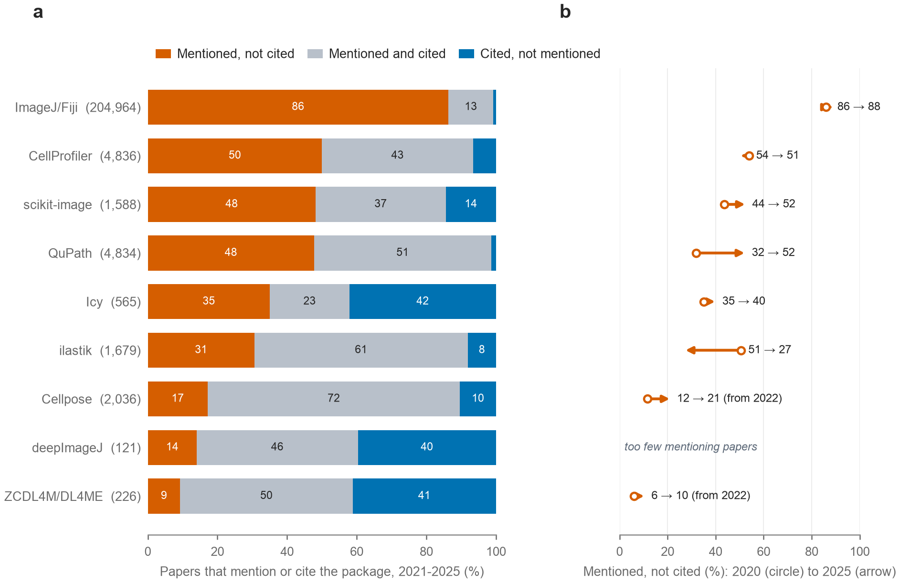

In [5]:
OUTPUT_STEM = 'Figure3__citations'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure3-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure3-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')